# R2 preprocessing and verification - all 42 participants

Core logic is in `scripts/r2_preprocessing.py`,
release checks in `r2_validation.py`, optional synthetic checks in `r2_checks.py`.
Default Run All audits the existing release. Candidate processing is explicit.


In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if not (ROOT/'configs/config.yaml').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'))
import r2_preprocessing as r2
from r2_validation import audit_release, make_epoch_qc
import pandas as pd


## 1. Execution controls

Leave processing disabled to inspect the published v2 release. Raw is absent; enable downloading only when deliberately processing new candidates.

In [2]:
RUN_PREPROCESS = False
DOWNLOAD_RAW = False
RUN_SYNTHETIC_TESTS = False
SUBJECTS = None  # None = all 42 configured IDs; [] = no work
if RUN_SYNTHETIC_TESTS:
    from r2_checks import test_r2
    test_r2()
if RUN_PREPROCESS:
    candidate_log = r2.run(ROOT, subjects=SUBJECTS, download=DOWNLOAD_RAW)


## 2. Verify the release and source events

In [3]:
audit = audit_release(ROOT)
display(pd.read_csv(ROOT/'results/preproc_log.csv'))


Considered: 42 Usable: 35 Excluded: 7
subject                                              exclusion_reason
 sub-02 paper: false alarms to distractors 98.8% (misunderstood task)
 sub-08                              target_retention_below_threshold
 sub-14 paper: false alarms to distractors 97.5% (misunderstood task)
 sub-17 paper: false alarms to distractors 76.5% (misunderstood task)
 sub-23                              target_retention_below_threshold
 sub-35                              target_retention_below_threshold
 sub-41                              target_retention_below_threshold
sub-01 591 matched_source_events
sub-03 618 matched_source_events
sub-04 650 matched_source_events
sub-05 623 matched_source_events
sub-06 627 matched_source_events
sub-07 296 matched_source_events
sub-09 635 matched_source_events
sub-10 269 matched_source_events
sub-11 607 matched_source_events
sub-12 651 matched_source_events
sub-13 510 matched_source_events
sub-15 645 matched_source_events
sub-16

,subject,pipeline_version,n_stimuli,standard_n,standard_correct,target_n,target_correct,distractor_n,distractor_correct,hit_rate,...,distractor_before,distractor_correct_trials,distractor_after,distractor_retained,raw_bytes,raw_source,visual_review_by,visual_review_date,visual_review_scope,qc_findings
0,sub-01,2,660.0,498.0,485.0,81.0,62.0,81.0,52.0,0.765432,...,81.0,52.0,52.0,1.000000,696750789.0,openneuro,Codex,2026-11-19,All retained-epoch PTP heatmaps and Pz average...,NaN
1,sub-02,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,Codex,2026-11-19,Excluded by existing release criteria; no reta...,NaN
2,sub-03,2,660.0,498.0,497.0,81.0,81.0,81.0,71.0,1.000000,...,81.0,71.0,70.0,0.985915,675352942.0,openneuro,Codex,2026-11-19,All retained-epoch PTP heatmaps and Pz average...,NaN
3,sub-04,2,660.0,498.0,498.0,81.0,79.0,81.0,76.0,0.975309,...,81.0,76.0,76.0,1.000000,673787878.0,openneuro,Codex,2026-11-19,All retained-epoch PTP heatmaps and Pz average...,NaN
4,sub-05,2,660.0,498.0,498.0,81.0,81.0,81.0,73.0,1.000000,...,81.0,73.0,68.0,0.931507,672121811.0,openneuro,Codex,2026-11-19,All retained-epoch PTP heatmaps and Pz average...,NaN
5,sub-06,2,660.0,498.0,497.0,81.0,78.0,81.0,78.0,0.962963,...,81.0,78.0,74.0,0.948718,675697786.0,openneuro,Codex,2026-11-19,All retained-epoch PTP heatmaps and Pz average...,NaN
6,sub-07,2,660.0,498.0,493.0,81.0,49.0,81.0,57.0,0.604938,...,81.0,57.0,34.0,0.596491,681996781.0,openneuro,Codex,2026-11-19,All retained-epoch PTP heatmaps and Pz average...,Elevated channel bands and lower target retent...
7,sub-08,2,660.0,498.0,496.0,81.0,69.0,81.0,69.0,0.851852,...,81.0,69.0,0.0,0.000000,861107772.0,openneuro,Codex,2026-11-19,Excluded by existing release criteria; no reta...,NaN
8,sub-09,2,660.0,498.0,498.0,81.0,71.0,81.0,74.0,0.876543,...,81.0,74.0,74.0,1.000000,673797604.0,openneuro,Codex,2026-11-19,All retained-epoch PTP heatmaps and Pz average...,NaN
9,sub-10,2,660.0,498.0,494.0,81.0,67.0,81.0,50.0,0.827160,...,81.0,50.0,22.0,0.440000,683928782.0,openneuro,Codex,2026-11-19,All retained-epoch PTP heatmaps and Pz average...,Persistent OI1h broadband noise; manual interp...


## 3. QC plots

Generating figures does not mean visual review is complete. Reviewed cases and decisions are recorded separately in the R2 handoff.

Created 35 subject QC figures


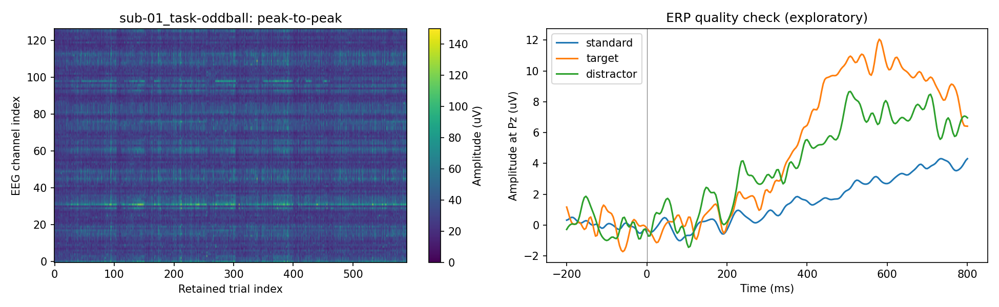

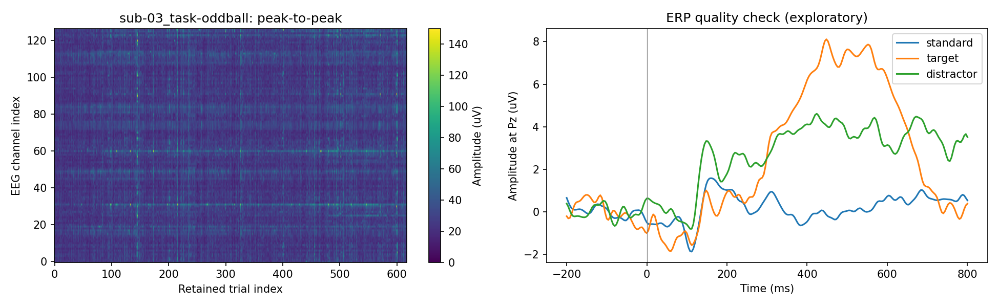

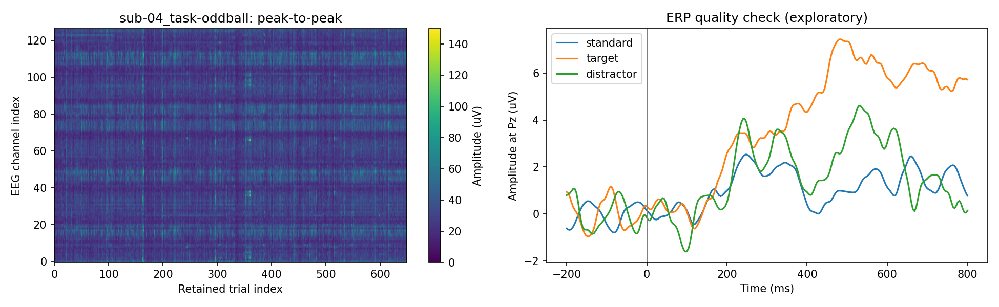

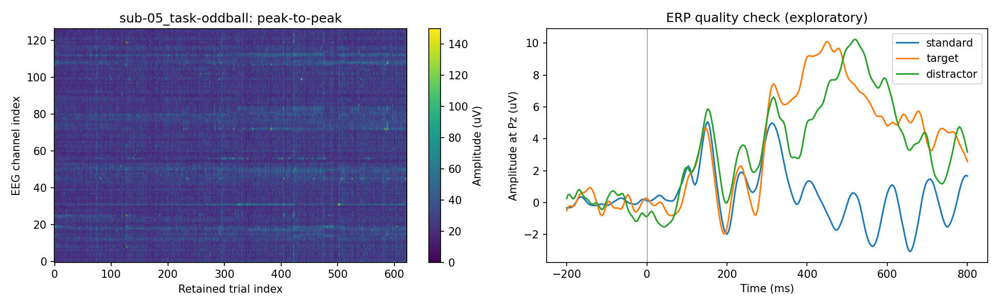

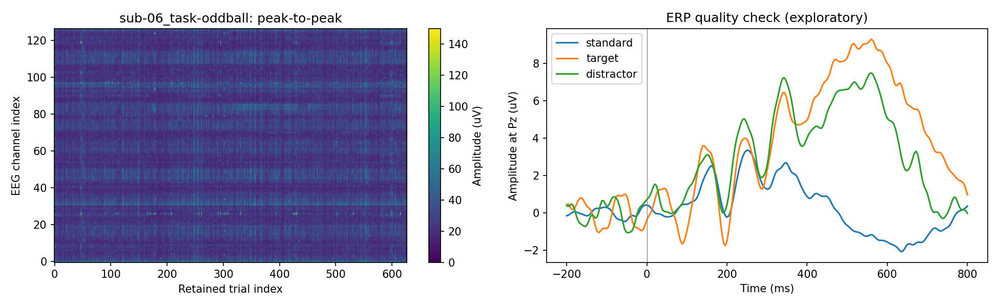

...

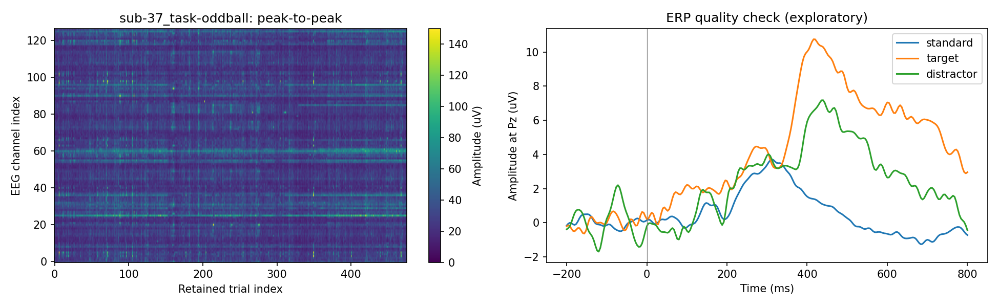

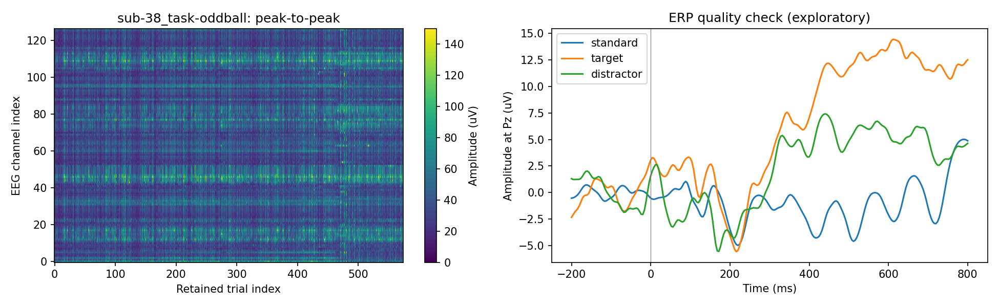

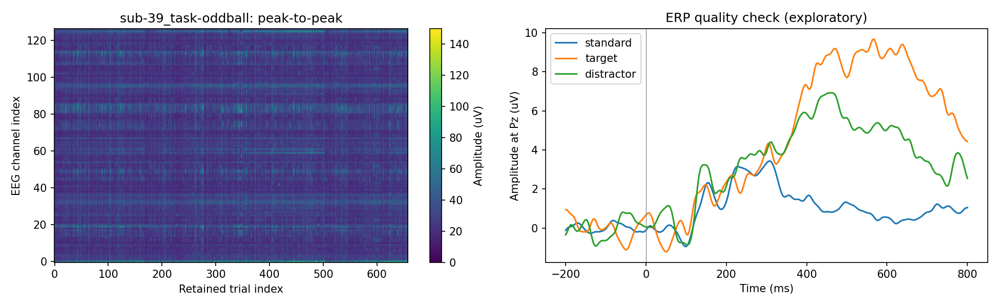

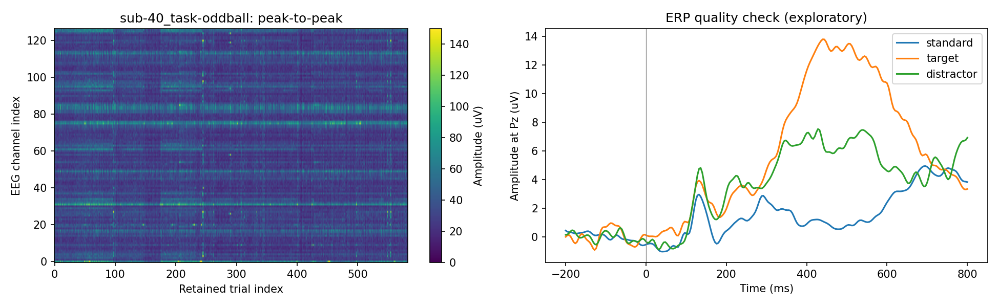

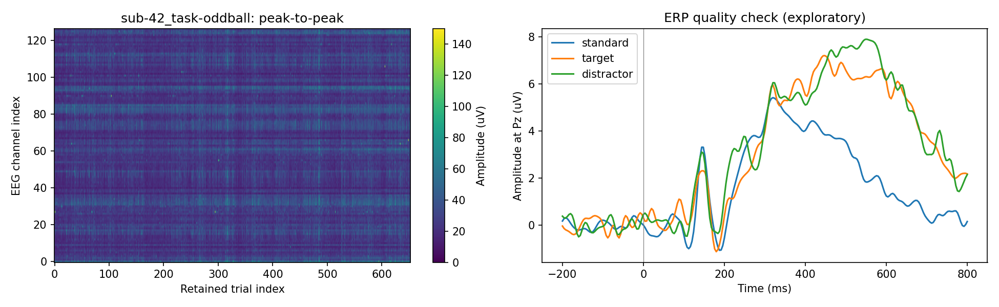

In [4]:
qc_paths = make_epoch_qc(ROOT)
print(f'Created {len(qc_paths)} subject QC figures')
from IPython.display import Image, display
for path in qc_paths:
    display(Image(filename=str(path)))


## Outputs and limitations

Published FIFs are unchanged. Candidates: `data/derivatives/preproc/_candidate/`;
candidate log/QC: `results/r2_candidate/`, `figures/preprocessing/candidate/`.
Audit: `results/v2_audit/`; complete R2 findings and Methods:
`reports/my_preprocessing_role_and_steps.md`.
See `reports/r2_qc_and_handoff.md` for actual review scope and unresolved decisions.
